# ELISA Results and Dairy Production Analysis

This notebook explores the relationship between Influenza A ELISA test results and robotic milking records. It first summarizes the ELISA results, checks for repeated cow IDs and conflicting test interpretations, and reviews the distribution of S/N values.

It then follows two cows as examples: Cow 69, which has a Positive ELISA result, and Cow 92, which has a Negative result. Their daily milk production is plotted and compared across a baseline period (August 15–September 15, 2024) and a later comparison period (September 28–October 5, 2024). The notebook also compares milking activity, refusals, and fat and protein indications where those columns are available.

The goal at this stage is exploratory: to identify changes in production and other milking measures that may be worth investigating in the larger dairy dataset. A difference between these two cows does not establish that infection caused a change. The duplicate ELISA records and the selected date ranges also need to be checked before drawing conclusions.

In [ ]:
import pandas as pd

df = pd.read_excel("Robot_dairy_results.xlsx")

In [ ]:
df.head()

,Cow_ID,Influenza A ELISA SN (S/N) Serum,Influenza A ELISA Interpretation Serum 05/22/25
0,301,0.13,Positive
1,123,0.48,Suspect
2,92,0.85,Negative
3,247,0.36,Positive
4,1,0.73,Negative


In [ ]:
df.shape

(211, 3)

In [ ]:
df["Cow_ID"].nunique()

204

In [ ]:
df["Cow_ID"].value_counts().head(15)

,count
Cow_ID,
8,2
1,2
3,2
2,2
500,2
10,2
7,2
269,1
247,1


In [ ]:
duplicates = df[df["Cow_ID"].duplicated(keep=False)]

duplicates.sort_values("Cow_ID")

,Cow_ID,Influenza A ELISA SN (S/N) Serum,Influenza A ELISA Interpretation Serum 05/22/25
4,1,0.73,Negative
194,1,0.25,Positive
124,2,0.67,Negative
196,2,0.90,Negative
118,3,0.60,Negative
192,3,0.76,Negative
176,7,0.35,Positive
207,7,0.39,Positive
11,8,0.45,Suspect
191,8,0.09,Positive


Initial EDA identified 211 ELISA records representing 204 unique cow IDs. Seven cows have duplicate records, and four of those cows have conflicting ELISA interpretations. These records require clarification before assigning a single infection label per cow.

In [ ]:
df.isnull().sum()

,0
Cow_ID,0
Influenza A ELISA SN (S/N) Serum,0
Influenza A ELISA Interpretation Serum 05/22/25,0


In [ ]:
df.columns

Index(['Cow_ID', 'Influenza A ELISA SN  (S/N)  Serum ',
       'Influenza A ELISA Interpretation  Serum  05/22/25 '],
      dtype='object')

In [ ]:
df.columns = [
    "Cow_ID",
    "ELISA_SN",
    "ELISA_Result"
]

In [ ]:
df.head()

,Cow_ID,ELISA_SN,ELISA_Result
0,301,0.13,Positive
1,123,0.48,Suspect
2,92,0.85,Negative
3,247,0.36,Positive
4,1,0.73,Negative


In [ ]:
df["ELISA_Result"].value_counts()

,count
ELISA_Result,
Negative,112
Positive,67
Suspect,32


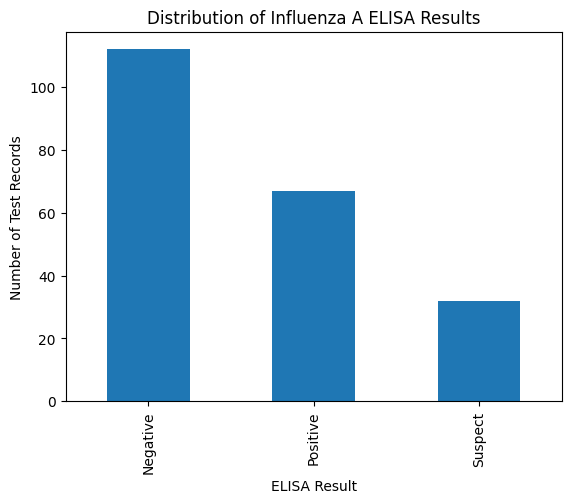

In [ ]:
import matplotlib.pyplot as plt

df["ELISA_Result"].value_counts().plot(kind="bar")

plt.title("Distribution of Influenza A ELISA Results")
plt.xlabel("ELISA Result")
plt.ylabel("Number of Test Records")
plt.show()

In [ ]:
df.groupby("ELISA_Result")["ELISA_SN"].mean()

,ELISA_SN
ELISA_Result,
Negative,0.826250
Positive,0.243582
Suspect,0.452188


Lower S/N values are associated with Positive results, while higher S/N values are associated with Negative results. Suspect results fall between them.

In [ ]:
df.groupby("ELISA_Result")["ELISA_SN"].describe()

,count,mean,std,min,25%,50%,75%,max
ELISA_Result,,,,,,,,
Negative,112.0,0.826250,0.330915,0.50,0.630,0.755,0.90,2.50
Positive,67.0,0.243582,0.089641,0.08,0.175,0.250,0.31,0.39
Suspect,32.0,0.452187,0.026849,0.40,0.440,0.450,0.48,0.49


S/N < 0.40 = Positive

0.40 – 0.49 = Suspect

S/N ≥ 0.50 = Negative

Observation: ELISA S/N values clearly separate the three interpretation categories in this dataset. Positive records range from 0.08–0.39, suspect records from 0.40–0.49, and negative records from 0.50–2.50. Seven cow IDs have multiple test records, including some with different S/N values and interpretations. These duplicate records require clarification before assigning one infection status to each cow.

In [ ]:
df.groupby("Cow_ID")["ELISA_Result"].nunique().sort_values(ascending=False).head(20)

,ELISA_Result
Cow_ID,
1,2
8,2
10,2
500,2
4,1
3,1
6,1
5,1
7,1


In [ ]:
conflicting_cows = df.groupby("Cow_ID")["ELISA_Result"].nunique()
conflicting_cows[conflicting_cows > 1]

,ELISA_Result
Cow_ID,
1,2
8,2
10,2
500,2


In [ ]:
df[df["Cow_ID"].isin(conflicting_cows[conflicting_cows > 1].index)].sort_values("Cow_ID")

,Cow_ID,ELISA_SN,ELISA_Result
4,1,0.73,Negative
194,1,0.25,Positive
11,8,0.45,Suspect
191,8,0.09,Positive
178,10,1.46,Negative
203,10,0.49,Suspect
158,500,0.43,Suspect
205,500,0.90,Negative


## Cow-level production analysis

In [ ]:
# Check for cows with conflicting ELISA results
result_counts = df.groupby("Cow_ID")["ELISA_Result"].nunique()
conflicting_ids = result_counts[result_counts > 1].index

# Keep positive cows with a single ELISA record
single_record_positive = df[
    (df["ELISA_Result"] == "Positive") &
    (~df["Cow_ID"].isin(df["Cow_ID"][df["Cow_ID"].duplicated(keep=False)]))
]

single_record_positive[["Cow_ID", "ELISA_Result", "ELISA_SN"]].head(10)

,Cow_ID,ELISA_Result,ELISA_SN
0,301,Positive,0.13
3,247,Positive,0.36
5,137,Positive,0.20
7,223,Positive,0.18
13,345,Positive,0.29
16,69,Positive,0.39
19,182,Positive,0.38
20,588,Positive,0.19
25,265,Positive,0.32
33,343,Positive,0.28


### Positive-result example: Cow 69

In [ ]:
xls = pd.ExcelFile("Robot Farm #69.xlsx")

xls.sheet_names

['Daily milk #69',
 'Quality #69',
 'Visits #69',
 'Lactation #69',
 'Events #69',
 'Feed #69']

In [ ]:
daily_df = pd.read_excel(
    "Robot Farm #69.xlsx",
    sheet_name="Daily milk #69"
)

daily_df.head(10)

,Date *,Lactation Days,Total Programmed,Rest Feed,Day Production,Day production Dev.,ISK,Milkings,Refusals,Failures,Milkings Avg.,Refusals Avg.,Failures Avg.,Fat indication,Protein indication,Lactose indication
0,AVG,NaN,12.53,0.22,99.4,NaN,163.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SUM,NaN,1892.57,32.75,15012.1,NaN,24698.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-10/15/2024,287.0,9.63,NaN,81.6,5.51,164.0,1.0,2.0,0,3.0,0.6,0.0,4.51,3.29,NaN
3,10/14/2024,286.0,9.28,0.17,80.2,4.85,161.2,4.0,0.0,0,3.4,0.3,0.0,4.64,3.30,NaN
4,10/13/3034,285.0,9.61,0.16,76.3,1.54,153.0,3.0,0.0,0,3.4,0.3,0.0,4.44,3.30,NaN
5,10/12/2024,284.0,9.22,0.11,80.0,5.73,160.7,3.0,0.0,0,3.4,0.6,0.0,4.09,3.32,NaN
6,10/11/2024,283.0,9.50,0.14,76.7,2.65,154.1,3.0,0.0,0,3.6,0.7,0.0,4.41,3.35,NaN
7,10/10/2024,282.0,9.10,0.14,79.1,4.19,159.0,4.0,1.0,0,3.6,1.6,0.0,4.13,3.35,NaN
8,10/9/2024,281.0,9.26,0.11,73.6,-2.20,148.1,3.0,1.0,0,3.6,1.4,0.0,4.29,3.36,NaN
9,10/8/2024,280.0,9.44,0.18,74.5,-2.65,140.9,4.0,0.0,0,3.6,1.4,0.0,4.29,3.35,NaN


In [ ]:
daily_ts = daily_df[
    ~daily_df["Date *"].isin(["AVG", "SUM"])
].copy()

daily_ts["Date *"] = pd.to_datetime(
    daily_ts["Date *"],
    errors="coerce"
)

print("Number of daily records:", len(daily_ts))
print("Missing dates:", daily_ts["Date *"].isna().sum())
print("Earliest date:", daily_ts["Date *"].min())
print("Latest date:", daily_ts["Date *"].max())

Number of daily records: 151
Missing dates: 150
Earliest date: 2024-10-15 00:00:00
Latest date: 2024-10-15 00:00:00


In [ ]:
print("Column type:", daily_df["Date *"].dtype)

daily_df["Date *"].head(12).map(repr)

Column type: object


,Date *
0,'AVG'
1,'SUM'
2,'-10/15/2024'
3,'10/14/2024'
4,'10/13/3034'
5,'10/12/2024'
6,'10/11/2024'
7,'10/10/2024'
8,'10/9/2024'
9,'10/8/2024'


In [ ]:
# Rebuild the time series from the original table
daily_ts = daily_df[
    ~daily_df["Date *"].isin(["AVG", "SUM"])
].copy()

# Preserve the source date values
daily_ts["Original_Date"] = daily_ts["Date *"]

# Remove leading hyphens from date values
date_values = (
    daily_ts["Date *"]
    .astype(str)
    .str.strip()
    .str.replace(r"^-", "", regex=True)
)

# Convert dates to datetime values
daily_ts["Date *"] = pd.to_datetime(
    date_values,
    format="%m/%d/%Y",
    errors="coerce"
)

print("Missing dates:", daily_ts["Date *"].isna().sum())

daily_ts.loc[
    daily_ts["Date *"].isna(),
    ["Original_Date", "Day Production"]
]

Missing dates: 1


,Original_Date,Day Production
4,10/13/3034,76.3


**Date-cleaning note:** One source date is recorded as `10/13/3034` and is changed to October 13, 2024 in the code below. This correction is based on the surrounding records, so it should be confirmed against the original farm spreadsheet.

In [ ]:
# Correct the apparent year-entry error
daily_ts.loc[
    daily_ts["Original_Date"].astype(str).str.strip() == "10/13/3034",
    "Date *"
] = pd.Timestamp("2024-10-13")

# Sort by date
daily_ts = daily_ts.sort_values("Date *")

# Check the cleaned dates
print("Missing dates:", daily_ts["Date *"].isna().sum())
print("Earliest date:", daily_ts["Date *"].min())
print("Latest date:", daily_ts["Date *"].max())

daily_ts[["Date *", "Day Production"]].head()

Missing dates: 0
Earliest date: 2024-05-18 00:00:00
Latest date: 2024-10-15 00:00:00


,Date *,Day Production
152,2024-05-18,86.2
151,2024-05-19,89.3
150,2024-05-20,89.3
149,2024-05-21,95.5
148,2024-05-22,95.7


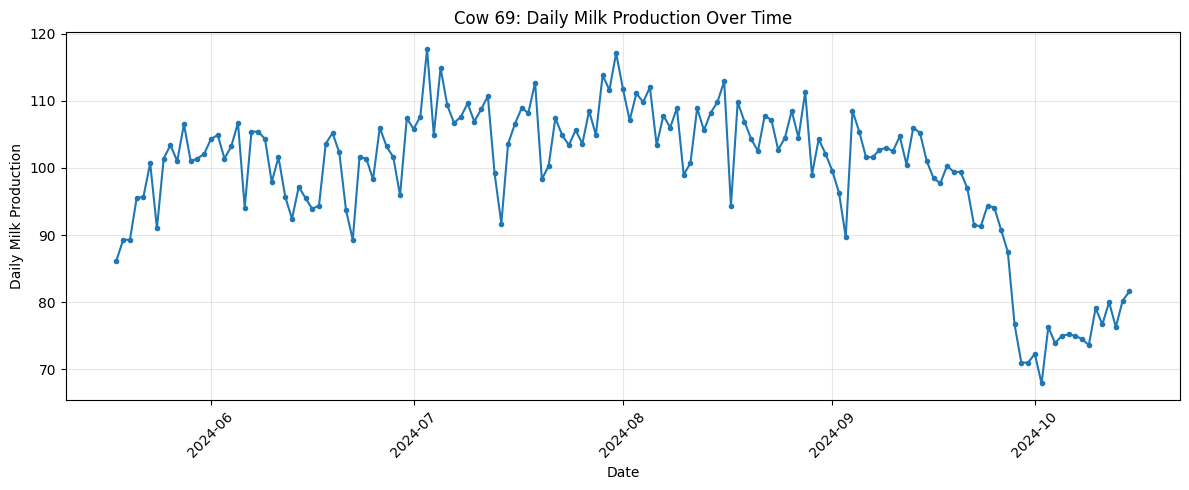

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    daily_ts["Date *"],
    daily_ts["Day Production"],
    marker="o",
    markersize=3
)

plt.title("Cow 69: Daily Milk Production Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Milk Production")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

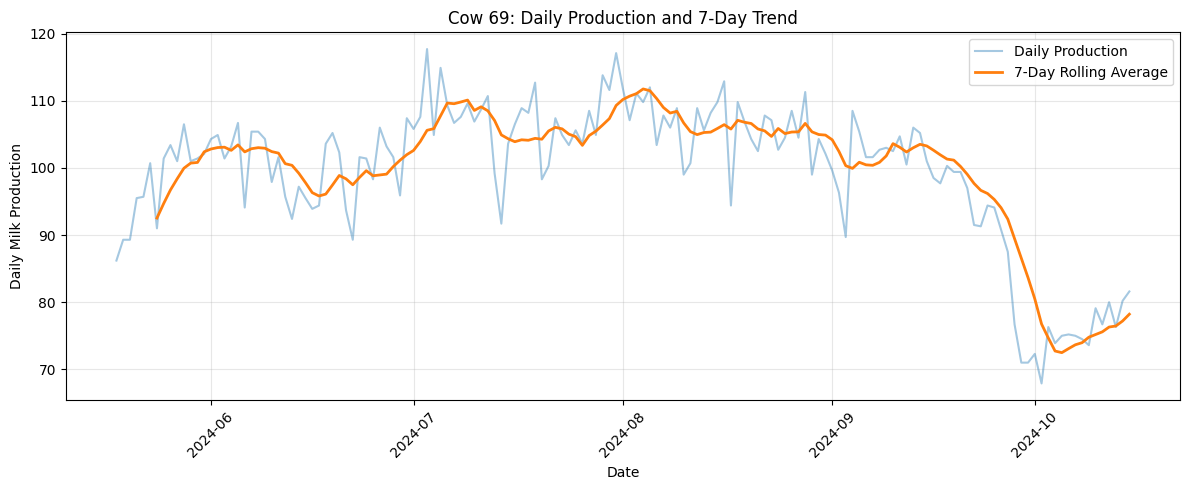

In [ ]:
# Calculate the 7-day rolling average
daily_ts["Production_7day_avg"] = (
    daily_ts["Day Production"]
    .rolling(window=7)
    .mean()
)

# Plot daily production with its 7-day average
plt.figure(figsize=(12, 5))

plt.plot(
    daily_ts["Date *"],
    daily_ts["Day Production"],
    alpha=0.4,
    label="Daily Production"
)

plt.plot(
    daily_ts["Date *"],
    daily_ts["Production_7day_avg"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("Cow 69: Daily Production and 7-Day Trend")
plt.xlabel("Date")
plt.ylabel("Daily Milk Production")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I started exploring the robotic milking data using Cow 69, whose ELISA result is Positive.

I cleaned the daily records and plotted milk production over time from May 18 to October 15, 2024.

The plot shows a substantial production decline in late September and early October.

Average daily production was 103.77 during August 15–September 15 and 73.01 during September 28–October 5, a decrease of approximately 29.64%.

I also calculated a seven-day rolling average, which confirms that the decline persisted across multiple days rather than being limited to one unusually low reading.

In [ ]:
# Set the baseline and comparison periods
baseline_mask = daily_ts["Date *"].between(
    "2024-08-15", "2024-09-15"
)

decline_mask = daily_ts["Date *"].between(
    "2024-09-28", "2024-10-05"
)

# Select production values for each period
baseline = daily_ts.loc[baseline_mask, "Day Production"]
decline = daily_ts.loc[decline_mask, "Day Production"]

# Calculate period averages
baseline_avg = baseline.mean()
decline_avg = decline.mean()

# Calculate the percentage change
percent_decline = (
    (baseline_avg - decline_avg) / baseline_avg
) * 100

print("Baseline average:", round(baseline_avg, 2))
print("Decline-period average:", round(decline_avg, 2))
print("Percentage decline:", round(percent_decline, 2), "%")
print("Baseline observations:", len(baseline))
print("Decline-period observations:", len(decline))

Baseline average: 103.77
Decline-period average: 73.01
Percentage decline: 29.64 %
Baseline observations: 32
Decline-period observations: 8


In [ ]:
# Compare milking activity across the two periods
behavior_columns = ["Milkings", "Refusals"]

for column in behavior_columns:
    baseline_mean = daily_ts.loc[baseline_mask, column].mean()
    decline_mean = daily_ts.loc[decline_mask, column].mean()

    print(f"\n{column}")
    print("Baseline average:", round(baseline_mean, 2))
    print("Decline-period average:", round(decline_mean, 2))


Milkings
Baseline average: 3.5
Decline-period average: 3.12

Refusals
Baseline average: 1.88
Decline-period average: 1.12


In [ ]:
print("Column type:", daily_ts["Failures"].dtype)

daily_ts["Failures"].value_counts(dropna=False).head(15)

Column type: object


,count
Failures,
0,138
1,11
0,1
Q,1


### Failures

The `Failures` column has not been analyzed yet.

### Negative-result example: Cow 92

Cow 92 is used as a comparison case because its ELISA result is Negative. The following cells prepare its daily production records and compare its measurements with Cow 69 over the same dates.

In [ ]:
# Identify cows with repeated ELISA records
duplicate_ids = df.loc[
    df["Cow_ID"].duplicated(keep=False),
    "Cow_ID"
].unique()

# Keep negative cows with a single ELISA record
negative_candidates = df.loc[
    (df["ELISA_Result"] == "Negative") &
    (~df["Cow_ID"].isin(duplicate_ids)),
    ["Cow_ID", "ELISA_SN"]
]

negative_candidates.head(10)

,Cow_ID,ELISA_SN
2,92,0.85
8,65,0.72
9,129,0.58
10,209,1.08
12,95,0.92
14,181,0.82
15,289,0.63
17,73,0.55
18,163,0.76
21,272,1.34


In [ ]:
negative_xls = pd.ExcelFile("Robot Farm #92.xlsx")
negative_xls.sheet_names

['Daily Milk', 'Quality', 'Visit', 'Events', 'Lactation', 'Feed']

In [ ]:
negative_daily = pd.read_excel(
    "Robot Farm #92.xlsx",
    sheet_name="Daily Milk"
)

negative_daily.head(10)

,Date »,Lactation Days,Total,Rest Feed,Day Production,Day production Dev.,ISK,Milkings,Refusals,Failures,Milkings Avg.,Refusals Avg.,Failures Avg.,Fat indication,Protein indication,Lactose indication
0,NaN,NaN,Programmed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AVC,NaN,15.06,0.38,112.1,NaN,144.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SUM,NaN,2138.51,54.21,15918.4,NaN,19798.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-10-15 00:00:00,141.0,13.96,NaN,106.9,-2.43,157.2,2.0,0.0,0.0,2.3,0.0,0.0,3.02,3.21,NaN
5,2024-10-14 00:00:00,140.0,14.29,2.40,99.9,-10.36,146.8,3.0,0.0,0.0,2.4,0.0,0.0,2.78,3.26,NaN
6,2024-10-13 00:00:00,139.0,14.62,1.91,96.3,-15.87,134.7,2.0,0.0,0.0,2.6,0.3,0.0,2.72,3.18,NaN
7,2024-10-12 00:00:00,138.0,14.95,3.06,93.0,-21.16,130.3,2.0,0.0,0.0,IV 29,0.3,0.0,2.73,3.14,NaN
8,2024-10-11 00:00:00,137.0,15.28,3.40,90.6,-25.35,126.8,2.0,0.0,0.0,NaN,0.3,0.0,3.08,3.19,NaN
9,2024-10-10 00:00:00,136.0,15.61,4.57,84.2,-34.17,117.9,2.0,0.0,0.0,""" 3.1",0.4,0.0,3.01,3.26,NaN


In [ ]:
negative_ts = negative_daily.iloc[4:].copy()

negative_ts = negative_ts.rename(
    columns={negative_ts.columns[0]: "Date"}
)

negative_ts[["Date", "Day Production"]].head()

,Date,Day Production
4,2024-10-15 00:00:00,106.9
5,2024-10-14 00:00:00,99.9
6,2024-10-13 00:00:00,96.3
7,2024-10-12 00:00:00,93.0
8,2024-10-11 00:00:00,90.6


In [ ]:
negative_ts["Original_Date"] = negative_ts["Date"]

negative_ts["Date"] = pd.to_datetime(
    negative_ts["Date"], errors="coerce"
)

negative_ts = negative_ts.sort_values("Date")

print("Rows:", len(negative_ts))
print("Earliest date:", negative_ts["Date"].min())
print("Latest date:", negative_ts["Date"].max())
print("Missing/invalid dates:", negative_ts["Date"].isna().sum())
print("Duplicate dates:", negative_ts["Date"].dropna().duplicated().sum())

Rows: 142
Earliest date: 2024-05-27 00:00:00
Latest date: 2024-10-15 00:00:00
Missing/invalid dates: 0
Duplicate dates: 0


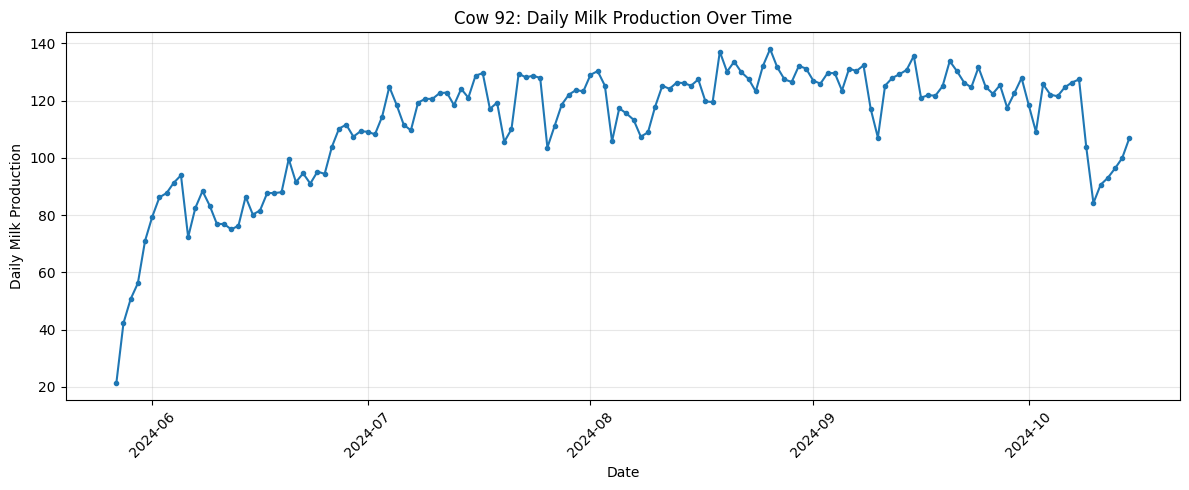

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    negative_ts["Date"],
    negative_ts["Day Production"],
    marker="o",
    markersize=3
)

plt.title("Cow 92: Daily Milk Production Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Milk Production")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
negative_baseline = negative_ts.loc[
    negative_ts["Date"].between("2024-08-15", "2024-09-15"),
    "Day Production"
]

negative_decline = negative_ts.loc[
    negative_ts["Date"].between("2024-09-28", "2024-10-05"),
    "Day Production"
]

baseline_avg = negative_baseline.mean()
decline_avg = negative_decline.mean()

percent_decline = (
    (baseline_avg - decline_avg) / baseline_avg
) * 100

print("Baseline average:", round(baseline_avg, 2))
print("Comparison-period average:", round(decline_avg, 2))
print("Percentage decline:", round(percent_decline, 2), "%")
print("Baseline valid observations:", negative_baseline.count())
print("Comparison-period valid observations:", negative_decline.count())

Baseline average: 127.95
Comparison-period average: 120.6
Percentage decline: 5.74 %
Baseline valid observations: 32
Comparison-period valid observations: 8


In [ ]:
negative_ts.loc[
    negative_ts["Date"].between("2024-10-01", "2024-10-15"),
    ["Date", "Day Production"]
]

,Date,Day Production
18,2024-10-01,118.4
17,2024-10-02,109.1
16,2024-10-03,125.7
15,2024-10-04,122.1
14,2024-10-05,121.5
13,2024-10-06,124.6
12,2024-10-07,126.3
11,2024-10-08,127.4
10,2024-10-09,103.8
9,2024-10-10,84.2


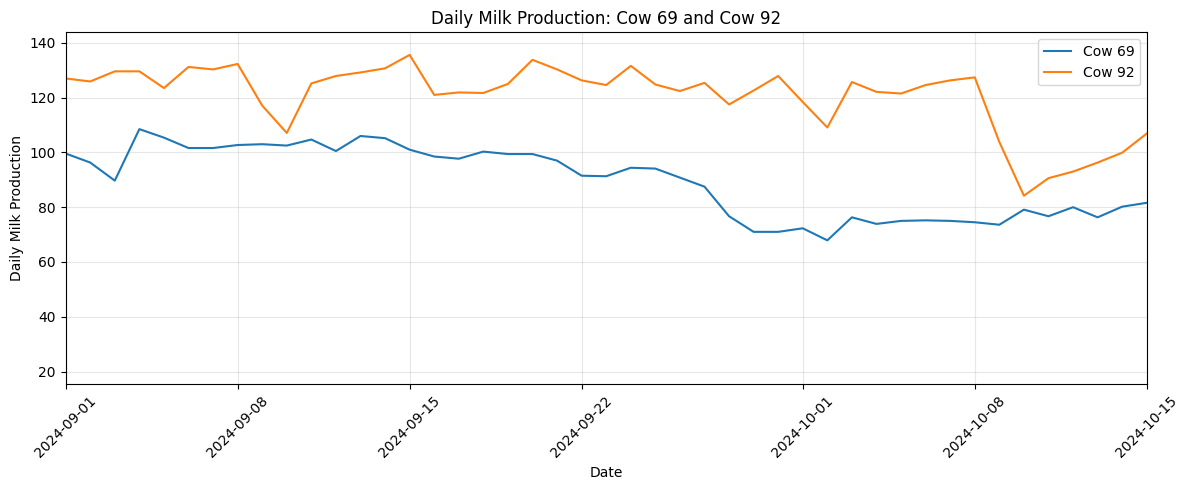

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_ts["Date *"], daily_ts["Day Production"],
    label="Cow 69"
)
plt.plot(
    negative_ts["Date"], negative_ts["Day Production"],
    label="Cow 92"
)

plt.xlim(pd.Timestamp("2024-09-01"), pd.Timestamp("2024-10-15"))
plt.title("Daily Milk Production: Cow 69 and Cow 92")
plt.xlabel("Date")
plt.ylabel("Daily Milk Production")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Fat and protein indications

Compare the fat and protein indication values over the same baseline and comparison periods for both cows.

In [ ]:
for column in ["Fat indication", "Protein indication"]:
    baseline = daily_ts.loc[
        daily_ts["Date *"].between("2024-08-15", "2024-09-15"),
        column
    ]

    decline = daily_ts.loc[
        daily_ts["Date *"].between("2024-09-28", "2024-10-05"),
        column
    ]

    print(column)
    print("Baseline average:", baseline.mean())
    print("Decline-period average:", decline.mean())
    print("Valid observations:", baseline.count(), decline.count())
    print()

Fat indication
Baseline average: 3.6696874999999998
Decline-period average: 3.9437499999999996
Valid observations: 32 8

Protein indication
Baseline average: 3.0609375
Decline-period average: 3.10375
Valid observations: 32 8



In [ ]:
for column in ["Fat indication", "Protein indication"]:
    baseline = negative_ts.loc[
        negative_ts["Date"].between("2024-08-15", "2024-09-15"),
        column
    ]

    decline = negative_ts.loc[
        negative_ts["Date"].between("2024-09-28", "2024-10-05"),
        column
    ]

    print(column)
    print("Baseline average:", baseline.mean())
    print("Comparison-period average:", decline.mean())
    print("Valid observations:", baseline.count(), decline.count())
    print()

Fat indication
Baseline average: 2.5384375
Comparison-period average: 2.59
Valid observations: 32 8

Protein indication
Baseline average: 3.0275
Comparison-period average: 3.24375
Valid observations: 32 8



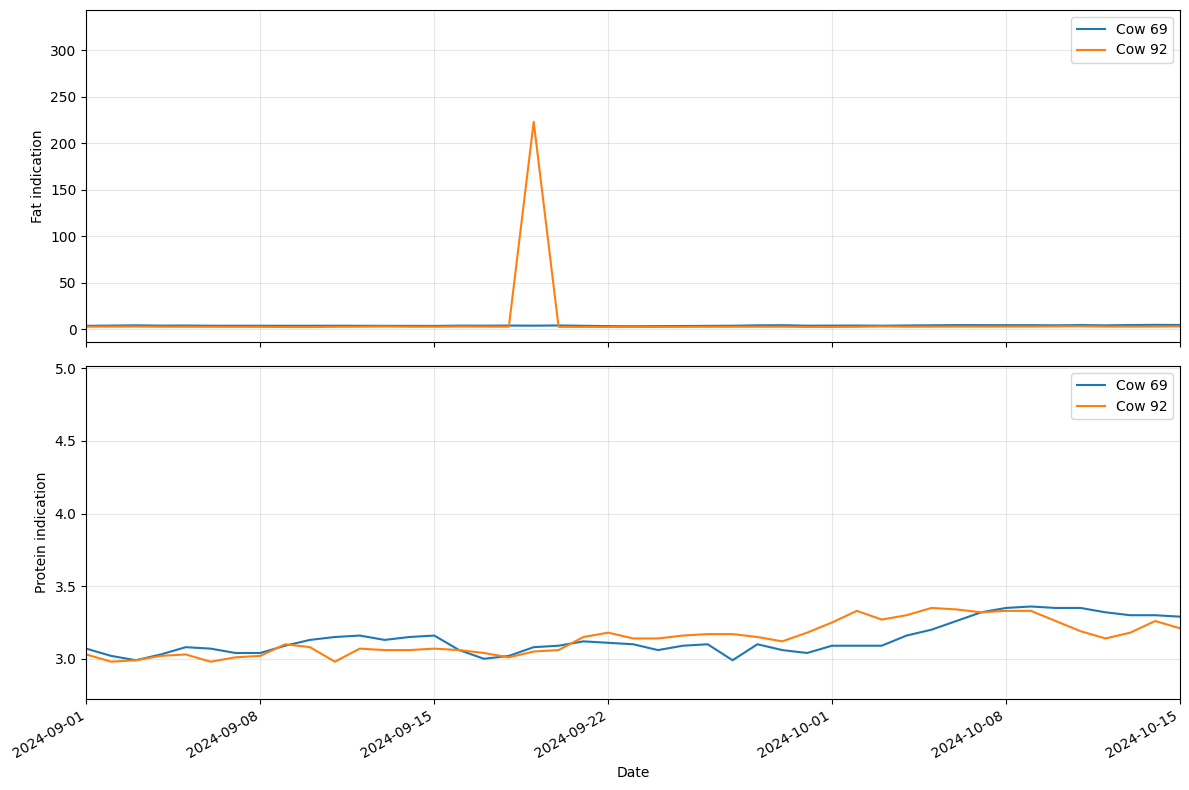

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for ax, column in zip(
    axes, ["Fat indication", "Protein indication"]
):
    ax.plot(daily_ts["Date *"], daily_ts[column], label="Cow 69")
    ax.plot(negative_ts["Date"], negative_ts[column], label="Cow 92")
    ax.set_ylabel(column)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[1].set_xlim(
    pd.Timestamp("2024-09-01"), pd.Timestamp("2024-10-15")
)
axes[1].set_xlabel("Date")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()